# Express Links · Week 2, steps 6 and 7: delayed match ρ and the express-link loop (Al Zahraa)

**Step 6.** For every ordered pair of sensors (u, v), measure the **delayed match ρ(u→v)**: after removing each sensor's usual daily and weekly pattern, how strongly does an unusual slowdown at u predict one at v, 5 to 60 minutes later? Keep the best delay and the direction. **Training period only.**
**Step 7.** The **express-link loop**: score every candidate pair by **ρ(u→v) × (total R saved by the link)**, add the best one-way link u→v with the weight of a typical existing link, update R, and repeat until K links are added. *Total R saved* = how much the link lowers the effective resistance summed over **all** pairs of sensors, not just between u and v (see section 6 for why this replaced ρ × R(u, v)).

No GPU needed: a CPU runtime, a few minutes. It processes every dataset whose files exist (METR-LA, PEMS-BAY, SHARJAH, TOY-C1) and skips the others with a message, so **rerun it when the toy city data arrives**.

**Reads (already in Drive)**

| What | Where | From |
|---|---|---|
| training samples | `data/processed/<dataset>/train.npz` | steps 2, 8, 11 |
| road graph | `data/raw/adj_mx.pkl`, `adj_mx_bay.pkl`, `data/raw/toy/<dataset>_adj_mx.pkl`, `data/raw/sharjah/SHARJAH_adj_mx.pkl` | steps 2, 8, 11 |
| districts ("across a bottleneck") | `data/processed/<dataset>/bottleneck/regions.npz`, `data/raw/toy/<dataset>_regions.json`, `data/raw/sharjah/SHARJAH_regions.json` | steps 5, 8, 11 |
| R, as a cross-check | `data/processed/<dataset>/resistance/resistance.npz` | step 4 |

**Writes**

| What | Where | Used by |
|---|---|---|
| ρ for every pair | `data/processed/<dataset>/rho/rho.npz` and `rho_pairs.csv` | step 10 (corr_only, same_side) |
| express graphs, K = 5, 10, 25, 50 | `data/graphs/<dataset>/express_K{K}.pkl` | step 12 (`express_K25.pkl`), step 15 (K sweep) |
| the links of each express graph | `data/graphs/<dataset>/express_K{K}_links.csv` | report |

**Choices made here (state them in the report):**

1. **Training series** = the speeds inside `train.npz` (the step-2 split), so ρ never sees validation or test data. Zeros are missing data and are skipped; gaps in time (PEMS-BAY's clock-change hour) stay missing so delays line up.
2. **Usual pattern** = the median speed of that sensor at that time of the week (7 days × 288 five-minute slots). We subtract it, then standardise each sensor's remainder.
3. **ρ(u→v)** = the largest correlation between u's remainder at time t and v's at t + d, over d = 5, 10, …, 60 minutes; the best d is the delay.
4. **True leaders only:** u→v is kept only if u leading beats v leading (ρ(u→v) > ρ(v→u)) **and** beats the same-time match (d = 0).
5. **Candidates for a link:** leader pairs with **ρ ≥ 0.2**, both sensors in the graph's main connected part, not already linked.
6. **Dead ends are excluded**, as step 5 defines them: sensors cut off by a single link that is their only connection (bridge score 1, 1–3 sensors). Their R is huge only because of that one link (in PEMS-BAY they cause all of the very highest R values), so the loop would otherwise spend links on them. Sensors behind a real bottleneck (step 5's `behind_bottleneck`, e.g. METR-LA's 9-sensor pocket) are **not** excluded: they are what express links are for. Set `EXCLUDE_DEAD_ENDS = False` to switch this off.
7. **Link weight** = median weight of the existing links. A link u→v sets `adj[u, v]`, so information flows from the leader u to the follower v, the way Graph WaveNet passes messages.
8. **Across a bottleneck** = the two sensors are in different districts (the team's step-5 rule). Used here only to report how many express links cross, and how much the K = 25 links shrink the gap between R across districts and R within a district.
9. **Score = ρ × total R saved** (`SCORE = 'total_R_saved'`). The older score ρ × R(u, v) is kept as `SCORE = 'pair_R'` for comparison.

## 1. Connect Google Drive

In [1]:
from google.colab import drive
drive.mount('/content/drive')

import os, glob

# Find the shared 'Coding' folder. It works whether the folder is in your own Drive or is
# your teammate's folder added to My Drive as a shortcut (Organize -> Add shortcut -> My Drive).
FOLDER = os.path.join('AdvML_F26_Project_&_Survey_Paper', 'Project', 'Coding')
ROOTS = ['/content/drive/MyDrive', '/content/drive/.shortcut-targets-by-id', '/content/drive/Shareddrives']
hits = []
for root in ROOTS:
    for depth in range(4):                      # the folder may sit up to 3 levels down
        hits += glob.glob(os.path.join(root, *(['*'] * depth), FOLDER))
hits = sorted(set(h for h in hits if os.path.isdir(os.path.join(h, 'data'))), key=len)
assert hits, ("Couldn't find the 'Coding' folder. In Google Drive open 'Shared with me', right-click "
              "'AdvML_F26_Project_&_Survey_Paper' -> Organize -> Add shortcut -> My Drive, then rerun this cell.")
PROJECT_DIR = hits[0]
print('PROJECT_DIR =', PROJECT_DIR)

# Results are written into the shared folder, so you need Editor access to it
try:
    probe = os.path.join(PROJECT_DIR, '.write_test')
    open(probe, 'w').close(); os.remove(probe)
    print('OK  you can write to this folder')
except OSError:
    raise PermissionError('You can read this folder but not write to it. Ask the owner to share it with you as Editor.')

Mounted at /content/drive
PROJECT_DIR = /content/drive/MyDrive/AdvML_F26_Project_&_Survey_Paper/Project/Coding
OK  you can write to this folder


## 2. Settings and inputs

In [2]:
import os, json, pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RAW_DIR   = os.path.join(PROJECT_DIR, 'data', 'raw')
PROC_DIR  = os.path.join(PROJECT_DIR, 'data', 'processed')
GRAPH_DIR = os.path.join(PROJECT_DIR, 'data', 'graphs')     # where step 12 looks for graph versions
FIG_DIR   = os.path.join(PROJECT_DIR, 'figures')
for d in [GRAPH_DIR, FIG_DIR]: os.makedirs(d, exist_ok=True)

DATASETS     = ['METR-LA', 'PEMS-BAY', 'SHARJAH', 'TOY-C1']   # every one whose files exist is processed
MAX_LAG      = 12            # delays of 1..12 steps = 5..60 minutes
RHO_MIN      = 0.2           # smallest delayed match that can become a link
EXCLUDE_DEAD_ENDS = True     # leave out sensors behind a single link that is their only connection (step 5's dead ends)
DEAD_END_MAX = 3             # up to this many sensors cut off by one link = a dead end (step 5's definition)
K_LIST       = [5, 10, 25, 50]
SCORE        = 'total_R_saved'   # 'total_R_saved' (default) or 'pair_R' (the first version: rho x R(u, v))

def first_existing(paths):
    return next((p for p in paths if os.path.exists(p)), None)

def find_inputs(name):
    '''This dataset's files, following the team's Drive layout; None where missing.'''
    special = {'METR-LA': 'adj_mx.pkl', 'PEMS-BAY': 'adj_mx_bay.pkl'}
    graph = first_existing(([os.path.join(RAW_DIR, special[name])] if name in special else []) +
                           [os.path.join(RAW_DIR, 'toy', f'{name}_adj_mx.pkl'),
                            os.path.join(RAW_DIR, 'sharjah', f'{name}_adj_mx.pkl')])
    regions = first_existing([os.path.join(PROC_DIR, name, 'bottleneck', 'regions.npz'),
                              os.path.join(RAW_DIR, 'toy', f'{name}_regions.json'),
                              os.path.join(RAW_DIR, 'sharjah', f'{name}_regions.json')])
    return dict(train=first_existing([os.path.join(PROC_DIR, name, 'train.npz')]), graph=graph, regions=regions,
                resistance=first_existing([os.path.join(PROC_DIR, name, 'resistance', 'resistance.npz')]))

INPUTS, READY = {}, []
for name in DATASETS:
    f = INPUTS[name] = find_inputs(name)
    missing = [k for k in ['train', 'graph'] if f[k] is None]
    if missing:
        print(f'SKIP  {name}: no {" or ".join(missing)} file yet; rerun this notebook once it is in Drive')
        continue
    READY.append(name)
    rel = lambda p: os.path.relpath(p, PROJECT_DIR) if p else 'not found'
    print(f'OK    {name}: graph {rel(f["graph"])} | districts {rel(f["regions"])} | step-4 R {rel(f["resistance"])}')
assert READY, 'No dataset has both train.npz and a road graph yet.'

OK    METR-LA: graph data/raw/adj_mx.pkl | districts data/processed/METR-LA/bottleneck/regions.npz | step-4 R data/processed/METR-LA/resistance/resistance.npz
OK    PEMS-BAY: graph data/raw/adj_mx_bay.pkl | districts data/processed/PEMS-BAY/bottleneck/regions.npz | step-4 R data/processed/PEMS-BAY/resistance/resistance.npz
OK    SHARJAH: graph data/raw/sharjah/SHARJAH_adj_mx.pkl | districts data/raw/sharjah/SHARJAH_regions.json | step-4 R not found
OK    TOY-C1: graph data/raw/toy/TOY-C1_adj_mx.pkl | districts data/raw/toy/TOY-C1_regions.json | step-4 R not found


## 3. Step 6: the delayed-match functions

`training_speeds` rebuilds the training period from `train.npz`: sample *s* holds raw rows `t_index[s] − 11 … t_index[s]`, so the last input reading of every sample (plus the first sample's earlier readings) gives every training row exactly once, with its timestamp.

`lagged_corr(Z)` returns, for every delay d = 0 … 12 steps, the matrix `C[d][u, v]` = correlation between u at time t and v at t + d, using only the time points where both sensors have a reading. All pairs are computed at once with matrix products.

In [3]:
def training_speeds(name):
    '''Training period as a (time x sensors) table; zeros and time gaps become NaN.'''
    z = np.load(INPUTS[name]['train'])
    x = z['x']
    S, N = x.shape[0], x.shape[2]
    t_index = z['t_index'].astype(int) if 't_index' in z.files else np.arange(11, 11 + S)
    if 't_anchor' in z.files:
        anchors = pd.to_datetime(z['t_anchor']).values
    else:   # no timestamps saved: 5-minute steps (time of day comes from feature 1 being regular)
        anchors = (pd.Timestamp('2000-01-03') + pd.to_timedelta(55 + 5 * np.arange(S), unit='min')).values
    rows = t_index - t_index[0] + 11
    X = np.full((rows[-1] + 1, N), np.nan)
    T = np.full(rows[-1] + 1, np.datetime64('NaT'), dtype='datetime64[ns]')
    X[rows], T[rows] = x[:, -1, :, 0], anchors
    X[:11] = x[0, :11, :, 0]
    T[:11] = anchors[0] - np.arange(11, 0, -1) * np.timedelta64(5, 'm')
    del x
    keep = ~np.isnat(T)
    df = pd.DataFrame(X[keep], index=pd.DatetimeIndex(T[keep]))
    df = df[~df.index.duplicated()].sort_index()
    df = df.reindex(pd.date_range(df.index[0], df.index[-1], freq='5min'))   # time gaps -> NaN rows
    return df.replace(0, np.nan)

def deseasonalise(df):
    '''Subtract each sensor's median speed at that time of the week, then standardise per sensor.'''
    slot = (df.index.dayofweek * 288 + df.index.hour * 12 + df.index.minute // 5).values
    X = df.to_numpy(dtype=float)
    usual = pd.DataFrame(X).groupby(slot).median().reindex(range(7 * 288)).to_numpy()
    r = X - usual[slot]
    with np.errstate(invalid='ignore', divide='ignore'):
        return (r - np.nanmean(r, 0)) / np.nanstd(r, 0)

def lagged_corr(Z, max_lag=MAX_LAG):
    '''C[d, u, v] = corr(Z[t, u], Z[t + d, v]) over time points where both are present, d = 0..max_lag.'''
    M = (~np.isnan(Z)).astype(float)
    Z0 = np.nan_to_num(Z)
    T = len(Z0); out = []
    for d in range(max_lag + 1):
        A, B, Ma, Mb = Z0[:T - d], Z0[d:], M[:T - d], M[d:]
        n = Ma.T @ Mb
        sx, sy, sxy = A.T @ Mb, Ma.T @ B, A.T @ B
        sxx, syy = (A * A).T @ Mb, Ma.T @ (B * B)
        with np.errstate(invalid='ignore', divide='ignore'):
            c = (n * sxy - sx * sy) / np.sqrt((n * sxx - sx ** 2) * (n * syy - sy ** 2))
        out.append(np.where(n >= 100, c, np.nan))          # need at least 100 shared readings
    return np.stack(out)

def delayed_match(C):
    '''rho(u->v), its delay in minutes, the same-time match, and whether u is a true leader of v.'''
    lead = np.nan_to_num(np.nanmax(np.where(np.isnan(C[1:]), -np.inf, C[1:]), axis=0), nan=0.0, neginf=0.0)
    delay = (np.argmax(np.nan_to_num(C[1:], nan=-9), axis=0) + 1) * 5
    same = np.nan_to_num(C[0], nan=0.0)
    leader = (lead > lead.T) & (lead > same) & ~np.eye(len(lead), dtype=bool)
    return lead, delay, same, leader

## 4. Check step 6 on a toy example with a known 20-minute delay

Three sensors over 8 weeks share the same rush-hour pattern. Sensor A has random jams; **sensor B copies A's jams exactly 20 minutes later**; sensor C has its own, unrelated jams. Some readings are missing. The checks:

* ρ(A→B) peaks at **20 minutes** and A is the leader (B is not the leader of A);
* C is not linked to A, **even though their raw speeds are clearly correlated** because of the shared rush hour. That is what removing the usual pattern is for.

In [4]:
rng = np.random.default_rng(0)
idx = pd.date_range('2020-01-06', periods=8 * 7 * 288, freq='5min')
tod = (idx.hour * 60 + idx.minute).to_numpy() / 60.0
weekday = idx.dayofweek.to_numpy() < 5
rush = 25 * (np.exp(-((tod - 8) / 1.0) ** 2) + np.exp(-((tod - 17.5) / 1.2) ** 2)) * weekday

def jams(n_jams, length=6):
    j = np.zeros(len(idx))
    for s in rng.choice(len(idx) - 50, n_jams, replace=False):
        j[s:s + length] += rng.uniform(15, 30)
    return j

jA, jC = jams(300), jams(300)
A = 65 - rush - jA + rng.normal(0, 2, len(idx))
B = 65 - rush - np.roll(jA, 4) + rng.normal(0, 2, len(idx))      # 4 steps = 20 minutes later
Cs = 65 - rush - jC + rng.normal(0, 2, len(idx))
toy = pd.DataFrame({'A': A, 'B': B, 'C': Cs}, index=idx)
toy.iloc[rng.choice(len(idx), 2000, replace=False), 1] = np.nan        # missing readings

lead, delay, same, leader = delayed_match(lagged_corr(deseasonalise(toy)))
raw_AC = toy['A'].corr(toy['C'])
print(f'rho(A->B) = {lead[0, 1]:.2f} at {delay[0, 1]} min; A leads B: {leader[0, 1]}; B leads A: {leader[1, 0]}')
print(f'raw speed correlation A-C = {raw_AC:.2f}  ->  after removing the usual pattern rho(A->C) = {lead[0, 2]:.2f}')
assert delay[0, 1] == 20 and leader[0, 1] and not leader[1, 0] and lead[0, 1] > 0.5
assert raw_AC > 0.3 and lead[0, 2] < 0.1 and lead[2, 0] < 0.1
print('OK  the known 20-minute delay and its direction are found; the shared rush hour is not mistaken for a link')

rho(A->B) = 0.93 at 20 min; A leads B: True; B leads A: False
raw speed correlation A-C = 0.40  ->  after removing the usual pattern rho(A->C) = 0.02
OK  the known 20-minute delay and its direction are found; the shared rush hour is not mistaken for a link


## 5. Step 6 on every dataset (training period only)

Saved per dataset in `data/processed/<dataset>/rho/`:

* `rho.npz`: `C` (13 × N × N, correlation by delay 0–60 min), `rho`, `delay_min`, `same_time`, `leader` (N × N), `sensor_ids`, `train_start`, `train_end`;
* `rho_pairs.csv`: one row per ordered pair (from, to, rho, delay_min, same_time, reverse_rho, leader). This is the ρ table of the plan; step 10's corr_only and same_side graphs are drawn from it.

In [5]:
def load_graph(name):
    with open(INPUTS[name]['graph'], 'rb') as f:
        sensor_ids, id_to_ind, adj = pickle.load(f, encoding='latin1')
    return sensor_ids, id_to_ind, np.asarray(adj, dtype=np.float32)

RHO = {}
for name in READY:
    sensor_ids, _, _ = load_graph(name)
    ids = [str(s) for s in sensor_ids]
    df = training_speeds(name)
    assert df.shape[1] == len(ids), f'{name}: data has {df.shape[1]} sensors, graph has {len(ids)}'
    C = lagged_corr(deseasonalise(df))
    lead, delay, same, leader = delayed_match(C)
    RHO[name] = dict(ids=ids, rho=lead, delay=delay, same=same, leader=leader)

    out = os.path.join(PROC_DIR, name, 'rho'); os.makedirs(out, exist_ok=True)
    np.savez_compressed(os.path.join(out, 'rho.npz'), C=C.astype(np.float32), rho=lead, delay_min=delay, same_time=same,
                        leader=leader, sensor_ids=np.array(ids), train_start=str(df.index[0]), train_end=str(df.index[-1]))
    u, v = np.where(~np.eye(len(ids), dtype=bool))
    pd.DataFrame({'from': np.array(ids)[u], 'to': np.array(ids)[v], 'rho': lead[u, v].round(4),
                  'delay_min': delay[u, v], 'same_time': same[u, v].round(4), 'reverse_rho': lead[v, u].round(4),
                  'leader': leader[u, v]}).to_csv(os.path.join(out, 'rho_pairs.csv'), index=False)

    off = ~np.eye(len(ids), dtype=bool)
    with np.errstate(invalid='ignore'):
        raw_same = np.nanmedian(np.corrcoef(np.nan_to_num(df.to_numpy() - np.nanmean(df.to_numpy(), 0)).T)[off])
    strong = leader & (lead >= RHO_MIN)
    print(f'==== {name}: {df.notna().any(axis=1).sum():,} training time points, {df.index[0]:%Y-%m-%d} to {df.index[-1]:%Y-%m-%d %H:%M}')
    print(f'  typical same-time match of two sensors: raw speeds {raw_same:.2f}, after removing the usual pattern {np.nanmedian(same[off]):.2f}')
    print(f'  ordered pairs with a true leader: {leader.sum():,} of {off.sum():,}; with rho >= {RHO_MIN}: {strong.sum():,}')
    if leader.any():
        print(f'  rho of true-leader pairs: median {np.median(lead[leader]):.2f}, 99th pct {np.percentile(lead[leader], 99):.2f}, max {lead[leader].max():.2f}')
    print(f'  saved {os.path.relpath(out, PROJECT_DIR)}/rho.npz and rho_pairs.csv\n')

==== METR-LA: 22,684 training time points, 2012-03-01 to 2012-05-23 06:40
  typical same-time match of two sensors: raw speeds 0.17, after removing the usual pattern 0.04
  ordered pairs with a true leader: 19,345 of 42,642; with rho >= 0.2: 881
  rho of true-leader pairs: median 0.06, 99th pct 0.40, max 0.78
  saved data/processed/METR-LA/rho/rho.npz and rho_pairs.csv

==== PEMS-BAY: 36,476 training time points, 2017-01-01 to 2017-05-07 16:35
  typical same-time match of two sensors: raw speeds 0.35, after removing the usual pattern 0.10
  ordered pairs with a true leader: 42,158 of 105,300; with rho >= 0.2: 9,143
  rho of true-leader pairs: median 0.11, 99th pct 0.42, max 0.87
  saved data/processed/PEMS-BAY/rho/rho.npz and rho_pairs.csv

==== SHARJAH: 24,187 training time points, 2024-01-01 to 2024-03-24 23:30
  typical same-time match of two sensors: raw speeds 0.79, after removing the usual pattern 0.06
  ordered pairs with a true leader: 40,093 of 89,700; with rho >= 0.2: 9,570
 

## 6. Step 7: the express-link loop

`express_links(...)` takes the road graph, ρ (with delays and leader flags), the Laplacian pseudoinverse L⁺ and K, and returns the graph with **exactly K added one-way links** plus the list of links. Each round:

1. score every candidate pair by **ρ(u→v) × S(u, v)**, where S(u, v) is the **total R saved**: how much adding the link u–v would lower the effective resistance summed over all pairs of sensors in the current graph;
2. add the best as a one-way link u→v with the typical link weight;
3. update L⁺ for the new link (exact one-link update) and recompute, so the next links do not pile up on the same bottleneck.

**How S is computed.** The sum of R over all pairs equals n · trace(L⁺). Adding a link of weight w between u and v, with b = e_u − e_v, lowers it by exactly

  S(u, v) = n · w · bᵀ(L⁺)²b / (1 + w · R(u, v)),

which is the same one-link (Sherman–Morrison) update used to refresh L⁺, so no search over the whole graph is needed. Section 7 checks it against recomputing the sum from scratch.

**Why not ρ × R(u, v) (our first version).** R(u, v) is large for any two far-apart sensors on thin edges of the network, for example two corners of the same district, not only for pairs on opposite sides of a bottleneck. On the toy city (one district boundary crossed by a single road), ρ × R put the first 2–3 links across the bridge and then spent the rest on corner pairs inside one district: 3 of 25 links crossed, and R across districts stayed about 2× R within one. S(u, v) rewards a link by how many routes it shortens, so a link that shortens every route across the bridge beats one that only helps two corners: 8 of 25 crossed and the gap fell to 1.37× (from 3.44× with no links). This is the "total effective resistance" view of over-squashing (Black et al., ICML 2023). Section 8 prints both scores for each dataset.

R treats the graph as two-way, as in step 4 (larger of the two directed weights, no self-links). The new link counts as a two-way connection when R is updated; the graph given to Graph WaveNet gets it in one direction only.

In [6]:
def undirected(adj):
    W = np.maximum(adj, adj.T).astype(float)
    np.fill_diagonal(W, 0)
    return W

def main_component(W):
    import scipy.sparse as sp, scipy.sparse.csgraph as cg
    _, lab = cg.connected_components(sp.csr_matrix(W > 0), directed=False)
    return lab == np.bincount(lab).argmax()

def laplacian_pinv(W):
    n = len(W); L = np.diag(W.sum(1)) - W; J = np.ones((n, n)) / n
    return np.linalg.inv(L + J) - J

def R_from_pinv(P):
    d = np.diag(P)
    R = d[:, None] + d[None, :] - 2 * P
    np.fill_diagonal(R, 0)
    return np.maximum(R, 0)

def add_link_update(P, u, v, w=1.0):
    '''L+ after adding a two-way link u-v of weight w (Sherman-Morrison).'''
    b = P[:, u] - P[:, v]
    return P - w * np.outer(b, b) / (1 + w * (b[u] - b[v]))

def total_R_saved(P, w):
    '''S[u, v] = drop in the sum of R over all pairs if a two-way link u-v of weight w is added.'''
    n = len(P); P2 = P @ P; d2 = np.diag(P2)
    Q = d2[:, None] + d2[None, :] - 2 * P2                  # b'(L+)^2 b for every pair
    S = n * w * Q / (1 + w * R_from_pinv(P))
    np.fill_diagonal(S, 0)
    return np.maximum(S, 0)

def total_R(P):
    return len(P) * np.trace(P)                              # sum of R over all unordered pairs

def express_links(adj, rho, delay, candidates, Lplus, in_main, K, weight, score_by=None):
    '''Greedy express-link placement. adj: (N, N) directed road graph. candidates: (N, N) bool, u->v allowed.
    Lplus: pseudoinverse on the in_main sensors. Returns the new adj and a table of the K links in order.'''
    N = len(adj)
    main = np.where(in_main)[0]
    pos = -np.ones(N, int); pos[main] = np.arange(len(main))
    cand = candidates & in_main[:, None] & in_main[None, :] & ~np.eye(N, dtype=bool)
    cand &= (adj == 0) & (adj.T == 0)                      # never duplicate an existing link
    score_by = score_by or SCORE
    new_adj, P, rows = adj.copy(), Lplus.copy(), []
    for k in range(K):
        R = np.zeros((N, N)); R[np.ix_(main, main)] = R_from_pinv(P)
        S = np.zeros((N, N)); S[np.ix_(main, main)] = total_R_saved(P, weight)
        score = np.where(cand, rho * (S if score_by == 'total_R_saved' else R), -np.inf)
        u, v = np.unravel_index(np.argmax(score), score.shape)
        if not np.isfinite(score[u, v]):
            print(f'  only {k} candidate links exist (asked for {K})')
            break
        rows.append(dict(rank=k + 1, from_idx=int(u), to_idx=int(v), rho=float(rho[u, v]),
                         delay_min=int(delay[u, v]), R_before=float(R[u, v]), R_saved=float(S[u, v]),
                         score=float(score[u, v])))
        new_adj[u, v] = weight
        P = add_link_update(P, pos[u], pos[v], weight)
        cand[u, v] = cand[v, u] = False
    return new_adj, pd.DataFrame(rows), P

## 7. Check step 7 on the 6-road example

The worked example from our methodology: two triangles (roads 1–3 and 4–6) joined by the bridge 3–4, with example delayed matches ρ(1→6) = 0.82, ρ(2→5) = 0.60, ρ(1→4) = 0.70.

* **First version (ρ × R), by hand:** round 1 adds **1→6** (0.82 × 2.33 = 1.91); after updating R, round 2 adds **2→5** (0.60 × 1.50 = 0.90), not 1→4 (0.70 × 0.83 = 0.58).
* **New score (ρ × total R saved):** S is checked against recomputing the sum of R from scratch for every possible link, and the loop must still pick two links across the bridge.

In [7]:
N6 = 6
adj6 = np.zeros((N6, N6))
for a, b in [(1,2),(1,3),(2,3),(3,4),(4,5),(4,6),(5,6)]:
    adj6[a-1, b-1] = adj6[b-1, a-1] = 1.0
rho6 = np.zeros((N6, N6)); delay6 = np.full((N6, N6), 20)
rho6[0, 5], rho6[1, 4], rho6[0, 3] = 0.82, 0.60, 0.70

# first version, against the hand calculation
new6, links6, _ = express_links(adj6, rho6, delay6, rho6 > 0, laplacian_pinv(adj6), np.ones(N6, bool), K=2, weight=1.0, score_by='pair_R')
got = [(r.from_idx + 1, r.to_idx + 1, round(r.score, 2)) for r in links6.itertuples()]
print('rho x R           links added (from, to, score):', got)
assert got == [(1, 6, 1.91), (2, 5, 0.90)], got
assert new6[0, 5] == 1 and new6[5, 0] == 0 and new6[1, 4] == 1 and new6[4, 1] == 0
assert (new6 != adj6).sum() == 2
print('OK  same links and scores as the worked example; exactly K one-way links, nothing else changed')

# total R saved, against brute force: add each possible link, recompute the sum of R from scratch
P6 = laplacian_pinv(adj6); S6 = total_R_saved(P6, 1.0)
for a in range(N6):
    for b in range(a + 1, N6):
        W2 = adj6.copy(); W2[a, b] += 1; W2[b, a] += 1
        assert np.isclose(total_R(P6) - total_R(laplacian_pinv(W2)), S6[a, b]), (a, b)
print(f'OK  total R saved matches brute force for all {N6 * (N6 - 1) // 2} possible links (sum of R now {total_R(P6):.2f})')
print('    S for the three candidates: 1-6 %.2f, 2-5 %.2f, 1-4 %.2f' % (S6[0, 5], S6[1, 4], S6[0, 3]))

new6s, links6s, _ = express_links(adj6, rho6, delay6, rho6 > 0, laplacian_pinv(adj6), np.ones(N6, bool), K=2, weight=1.0)
got_s = [(r.from_idx + 1, r.to_idx + 1, round(r.score, 2)) for r in links6s.itertuples()]
print('rho x total saved links added (from, to, score):', got_s)
assert {(a, b) for a, b, _ in got_s} == {(1, 6), (2, 5)}, got_s     # both cross the bridge 3-4
print('OK  the new score also puts both links across the bridge')

rho x R           links added (from, to, score): [(1, 6, 1.91), (2, 5, 0.9)]
OK  same links and scores as the worked example; exactly K one-way links, nothing else changed
OK  total R saved matches brute force for all 15 possible links (sum of R now 21.00)
    S for the three candidates: 1-6 8.30, 2-5 8.30, 1-4 6.50
rho x total saved links added (from, to, score): [(1, 6, 6.81), (2, 5, 1.98)]
OK  the new score also puts both links across the bridge


## 8. Step 7 on every dataset

The loop runs once with K = 50; because it is greedy, the first 5, 10 and 25 links are exactly the K = 5, 10 and 25 graphs. Each graph is saved in the original format `(sensor_ids, sensor_id_to_ind, adj)` as `data/graphs/<dataset>/express_K{K}.pkl`, the name step 12 looks for (`express_K25.pkl`), with the list of its links next to it.

R is recomputed here from the road graph and **checked against step 4's `resistance.npz`** where it exists. It also reports the week-1 go/no-go check: how many candidate pairs have **both** a strong delayed match and R in the top 10 %?

For every dataset with districts it also prints a **comparison of the two scores at K = 25**: how many links cross a district boundary, the mean ρ of the links, and the **bottleneck gap** = median R between sensors in different districts ÷ median R between sensors in the same district (1 means no bottleneck left).

In [8]:
def dead_ends(W, R, in_main, max_size=DEAD_END_MAX):
    '''Sensors cut off from the main part by one link (bridge score W*R = 1), at most max_size of them.'''
    import scipy.sparse as sp, scipy.sparse.csgraph as cg
    out = np.zeros(len(W), bool)
    iu, iv = np.nonzero(np.triu(W > 0, 1))
    for a, b in zip(iu, iv):
        if in_main[a] and in_main[b] and W[a, b] * R[a, b] >= 0.999:
            W2 = W.copy(); W2[a, b] = W2[b, a] = 0
            _, lab = cg.connected_components(sp.csr_matrix(W2[np.ix_(in_main, in_main)] > 0), directed=False)
            sizes = np.bincount(lab)
            small = np.flatnonzero(in_main)[lab == np.argmin(sizes)]
            if len(small) <= max_size:
                out[small] = True
    return out

def load_districts(name, ids):
    '''District of every sensor (the team's step-5 rule); None if no regions file exists.'''
    p = INPUTS[name]['regions']
    if p is None:
        return None
    if p.endswith('.npz'):
        z = np.load(p)
        d = dict(zip([str(s) for s in z['sensor_ids']], z['district'].tolist()))
    else:
        with open(p) as f:
            d = {str(k): v for k, v in json.load(f)['district'].items()}
    return np.array([str(d.get(s, -1)) for s in ids])

EXPRESS = {}
for name in READY:
    sensor_ids, id_to_ind, adj = load_graph(name)
    r = RHO[name]; ids = r['ids']; N = len(ids); off = ~np.eye(N, dtype=bool)
    W = undirected(adj); in_main = main_component(W)
    Lplus = laplacian_pinv(W[np.ix_(in_main, in_main)])
    R = np.full((N, N), np.inf); R[np.ix_(in_main, in_main)] = R_from_pinv(Lplus)

    if INPUTS[name]['resistance']:
        R4 = np.load(INPUTS[name]['resistance'])['R']
        same_R = np.allclose(R[np.ix_(in_main, in_main)], R4[np.ix_(in_main, in_main)], rtol=1e-6, atol=1e-8)
        print(f'{"OK " if same_R else "!! "} {name}: R matches step 4\'s resistance.npz' if same_R else
              f'!!  {name}: R differs from step 4\'s resistance.npz; check both before using the graphs')

    district = load_districts(name, ids)
    weight = float(np.median(adj[(adj > 0) & off]))
    strength = W.sum(1)
    weak = dead_ends(W, R, in_main) if EXCLUDE_DEAD_ENDS else np.zeros(N, bool)
    strong = r['leader'] & (r['rho'] >= RHO_MIN) & (adj == 0) & (adj.T == 0) & in_main[:, None] & in_main[None, :]
    candidates = strong & ~weak[:, None] & ~weak[None, :]
    R_top = np.percentile(R[np.ix_(in_main, in_main)][np.triu_indices(in_main.sum(), 1)], 90)
    go = int((strong & (R >= R_top)).sum())

    new_adj, links, _ = express_links(adj, r['rho'], r['delay'], candidates, Lplus, in_main, max(K_LIST), weight)
    links['from'] = [ids[i] for i in links.from_idx]; links['to'] = [ids[i] for i in links.to_idx]
    links['crosses_district'] = (district[links.from_idx] != district[links.to_idx]) if district is not None else np.nan
    EXPRESS[name] = dict(links=links, adj=adj, ids=ids, district=district)

    out = os.path.join(GRAPH_DIR, name); os.makedirs(out, exist_ok=True)
    for K in K_LIST:
        if K > len(links):
            print(f'  not enough candidate links for K = {K}; express_K{K}.pkl not written')
            continue
        a = adj.copy()
        for row in links.head(K).itertuples():
            a[row.from_idx, row.to_idx] = weight
        assert int(((a > 0) & ~(adj > 0)).sum()) == K and (a[adj > 0] == adj[adj > 0]).all()
        with open(os.path.join(out, f'express_K{K}.pkl'), 'wb') as f:
            pickle.dump((sensor_ids, id_to_ind, a), f, protocol=2)
        links.head(K)[['rank', 'from', 'to', 'rho', 'delay_min', 'R_before', 'R_saved', 'score', 'crosses_district']].round(4).to_csv(
            os.path.join(out, f'express_K{K}_links.csv'), index=False)

    k25 = links.head(25)
    behind = None
    if INPUTS[name]['regions'] and INPUTS[name]['regions'].endswith('.npz'):
        zb = np.load(INPUTS[name]['regions'])
        if 'behind_bottleneck' in zb.files:
            behind = dict(zip([str(x) for x in zb['sensor_ids']], zb['behind_bottleneck'].tolist()))
    n_d = 'no districts file' if district is None else f'{len(set(district) - {"-1"})} district(s)'
    print(f'==== {name}: link weight {weight:.3f}; {weak.sum()} dead-end sensors excluded ({", ".join(ids[i] for i in np.flatnonzero(weak)) or "none"}); {candidates.sum():,} candidate pairs; {n_d}')
    print(f'  go/no-go: strong leader pairs (rho >= {RHO_MIN}) with R in the top 10%: {go}')
    if len(k25):
        cross = 'n/a' if district is None else f'{int(k25.crosses_district.sum())} of {len(k25)}'
        print(f'  K = 25: links crossing a district boundary: {cross}; mean rho {k25.rho.mean():.2f}, '
              f'mean R {k25.R_before.mean():.2f}, median delay {k25.delay_min.median():.0f} min; '
              f'{len(set(k25["from"]) | set(k25["to"]))} distinct sensors')
        if behind is not None:
            touch = [behind.get(a, False) or behind.get(b, False) for a, b in zip(k25['from'], k25['to'])]
            print(f'  K = 25 links touching a sensor behind the bottleneck (step 5): {sum(touch)} of {len(k25)}')
        if district is not None and len(set(district[in_main])) > 1:
            dm = district[in_main]; cr = dm[:, None] != dm[None, :]; same = ~cr & ~np.eye(len(dm), dtype=bool)
            gap = lambda P: np.median(R_from_pinv(P)[cr]) / np.median(R_from_pinv(P)[same])
            print(f'  bottleneck gap (R across / R within districts): no links {gap(Lplus):.2f}')
            for sb in ['total_R_saved', 'pair_R']:
                _, lk, P25 = express_links(adj, r['rho'], r['delay'], candidates, Lplus, in_main, 25, weight, score_by=sb)
                nc = int((district[lk.from_idx] != district[lk.to_idx]).sum())
                tag = 'rho x total R saved' if sb == 'total_R_saved' else 'rho x R(u,v) (first version)'
                print(f'    {tag:30s}: {nc:2d} of {len(lk)} links cross, mean rho {lk.rho.mean():.2f}, gap after K = 25 {gap(P25):.2f}')
        print(k25.head(8)[['rank', 'from', 'to', 'rho', 'delay_min', 'R_before', 'R_saved', 'score', 'crosses_district']].round(2).to_string(index=False))
    print(f'  saved in {os.path.relpath(out, PROJECT_DIR)}: ' + ', '.join(f'express_K{K}.pkl' for K in K_LIST if K <= len(links)) + '\n')

OK  METR-LA: R matches step 4's resistance.npz
==== METR-LA: link weight 0.320; 0 dead-end sensors excluded (none); 570 candidate pairs; 2 district(s)
  go/no-go: strong leader pairs (rho >= 0.2) with R in the top 10%: 0
  K = 25: links crossing a district boundary: 3 of 25; mean rho 0.28, mean R 1.19, median delay 20 min; 33 distinct sensors
  K = 25 links touching a sensor behind the bottleneck (step 5): 3 of 25
  bottleneck gap (R across / R within districts): no links 5.73
    rho x total R saved           :  3 of 25 links cross, mean rho 0.28, gap after K = 25 6.60
    rho x R(u,v) (first version)  :  2 of 25 links cross, mean rho 0.37, gap after K = 25 6.03
 rank   from     to  rho  delay_min  R_before  R_saved  score  crosses_district
    1 773012 765273 0.30         30      1.76  1156.02 350.47             False
    2 718066 765265 0.22         20      1.36  1000.83 217.18             False
    3 767554 767609 0.27          5      1.92   617.53 165.43              True
    4 71

## 9. Figure: where the K = 25 express links go (METR-LA and PEMS-BAY)

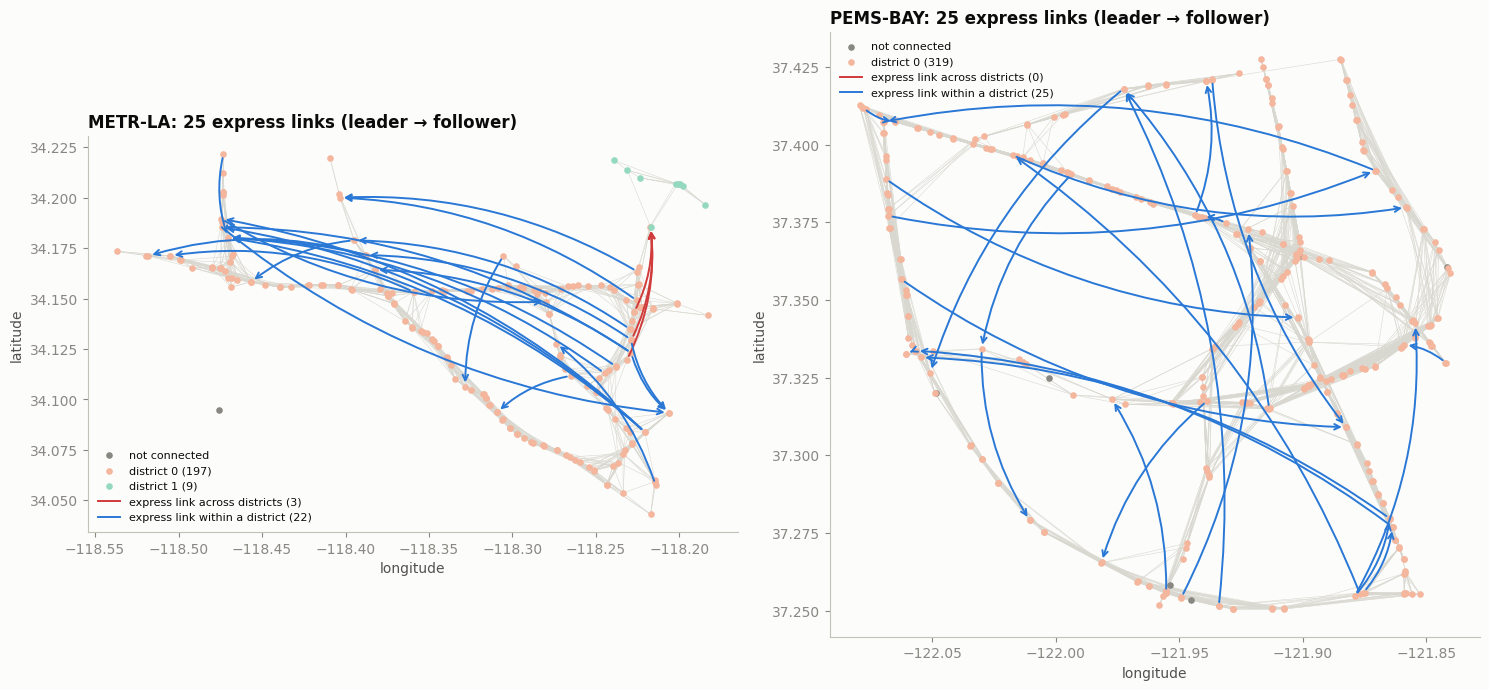

In [9]:
INK, MUTED = '#0b0b0b', '#898781'
plt.rcParams.update({'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb', 'axes.edgecolor': '#c3c2b7',
                     'axes.labelcolor': '#52514e', 'xtick.color': MUTED, 'ytick.color': MUTED, 'text.color': INK,
                     'axes.spines.top': False, 'axes.spines.right': False, 'font.size': 10,
                     'axes.titlesize': 12, 'axes.titleweight': 'bold'})
LOC = {'METR-LA': ('graph_sensor_locations.csv', True), 'PEMS-BAY': ('graph_sensor_locations_bay.csv', False)}
DIST_COLORS = ['#9cc3ef', '#f4b69c', '#94d9bf', '#cdb1db', '#ead08b']

def locations(name, ids):
    f, header = LOC[name]; path = os.path.join(RAW_DIR, f)
    loc = pd.read_csv(path)[['sensor_id', 'latitude', 'longitude']] if header else \
          pd.read_csv(path, header=None, names=['sensor_id', 'latitude', 'longitude'])
    loc['sensor_id'] = loc['sensor_id'].astype(str)
    return loc.set_index('sensor_id').loc[ids, ['latitude', 'longitude']].to_numpy()

shown = [n for n in EXPRESS if n in LOC and os.path.exists(os.path.join(RAW_DIR, LOC[n][0]))]
if shown:
    fig, axes = plt.subplots(1, len(shown), figsize=(7.5 * len(shown), 7.5), squeeze=False)
    for ax, name in zip(axes[0], shown):
        e = EXPRESS[name]; xy = locations(name, e['ids']); adj = e['adj']
        i, j = np.where(np.triu(np.maximum(adj, adj.T) > 0, 1))
        for a, b in zip(i, j):
            ax.plot([xy[a, 1], xy[b, 1]], [xy[a, 0], xy[b, 0]], color='#d9d8d0', lw=0.4, zorder=1)
        dist = e['district'] if e['district'] is not None else np.array(['0'] * len(e['ids']))
        for k, dname in enumerate(sorted(set(dist))):
            s = dist == dname
            ax.scatter(xy[s, 1], xy[s, 0], s=14, zorder=2, color=MUTED if dname == '-1' else DIST_COLORS[k % 5],
                       label='not connected' if dname == '-1' else f'district {dname} ({s.sum()})')
        k25 = e['links'].head(25)
        crosses = k25['crosses_district'].fillna(False).astype(bool)
        for row, c in zip(k25.itertuples(), crosses):
            a, b = row.from_idx, row.to_idx
            ax.annotate('', xy=(xy[b, 1], xy[b, 0]), xytext=(xy[a, 1], xy[a, 0]), zorder=3,
                        arrowprops=dict(arrowstyle='->', color='#d03b3b' if c else '#2a78d6', lw=1.4,
                                        shrinkA=3, shrinkB=3, connectionstyle='arc3,rad=0.15'))
        ax.plot([], [], color='#d03b3b', lw=1.4, label=f'express link across districts ({crosses.sum()})')
        ax.plot([], [], color='#2a78d6', lw=1.4, label=f'express link within a district ({(~crosses).sum()})')
        ax.set_title(f'{name}: 25 express links (leader → follower)', loc='left')
        ax.set_xlabel('longitude'); ax.set_ylabel('latitude')
        ax.set_aspect(1 / np.cos(np.deg2rad(np.nanmean(xy[:, 0])))); ax.legend(frameon=False, fontsize=8, loc='best')
    fig.tight_layout()
    fig.savefig(os.path.join(FIG_DIR, 'express_links_K25_map.png'), dpi=200, bbox_inches='tight')
    plt.show()

## Done

* **Step 6:** `data/processed/<dataset>/rho/rho.npz` and `rho_pairs.csv`, from training data only, checked on a toy example with a known 20-minute delay.
* **Step 7:** `data/graphs/<dataset>/express_K{5,10,25,50}.pkl` with their link lists, built by the ρ × total-R-saved loop, checked against the 6-road worked example and a brute-force check of the score. Step 12 picks up `express_K25.pkl` automatically (its status board turns the express runs from `blocked` to `not_started`).

Rerun this notebook when `data/processed/TOY-C1/` and `data/raw/toy/TOY-C1_adj_mx.pkl` exist: it will add the toy city's ρ and express graphs without changing the others.